House Value Prediction Using Simple Linear Regression

Internship: Codveda Technologies, Machine Learning

Level: Level 1, Basic

Task: Simple Linear Regression

Objective: Develop a simple linear regression model to predict median house values using the average number of rooms in a house. The project includes data loading, preprocessing, training, coefficient interpretation, and model evaluatison using R² and Mean Squared Error (MSE).

In [ ]:
import pandas as pd

file_id = "1HZl785L4UV7YR8lVf8GtLvqFiiKxe_hB"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

columns = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"
]

df = pd.read_csv(url, sep=r"\s+", header=None)
df.columns = columns

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df[["RM", "MEDV"]].isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSummary statistics for RM and MEDV:")
display(df[["RM", "MEDV"]].describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB

Missing values:
RM      0
MEDV    0
dtype: int64

Duplicate rows:
0

Summary statistics for RM and MEDV:


,RM,MEDV
count,506.000000,506.000000
mean,6.284634,22.532806
std,0.702617,9.197104
min,3.561000,5.000000
25%,5.885500,17.025000
50%,6.208500,21.200000
75%,6.623500,25.000000
max,8.780000,50.000000


In [ ]:
# Select the input feature and target variable
X = df[["RM"]]
y = df["MEDV"]

print("Input feature: RM (average number of rooms)")
print("Target variable: MEDV (median house value)")

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input feature: RM (average number of rooms)
Target variable: MEDV (median house value)

Input shape: (506, 1)
Target shape: (506,)


,RM
0,6.575
1,6.421
2,7.185
3,6.998
4,7.147


,MEDV
0,24.0
1,21.6
2,34.7
3,33.4
4,36.2


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 404
Testing samples: 102


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Linear Regression model trained successfully!
Intercept: -36.24631889813795
Coefficient: 9.348301406497727


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
------------------------
Mean Squared Error (MSE): 46.1448
R² Score: 0.3708


In [ ]:
results = pd.DataFrame({
    "Actual MEDV": y_test.values,
    "Predicted MEDV": y_pred
})

results["Prediction Error"] = (
    results["Actual MEDV"] - results["Predicted MEDV"]
)

display(results.head(10).round(2))

,Actual MEDV,Predicted MEDV,Prediction Error
0,23.6,23.73,-0.13
1,32.4,26.93,5.47
2,13.6,19.68,-6.08
3,22.8,20.45,2.35
4,16.1,22.62,-6.52
5,20.0,22.45,-2.45
6,17.8,19.04,-1.24
7,14.0,21.47,-7.47
8,19.6,21.98,-2.38
9,16.8,20.10,-3.30


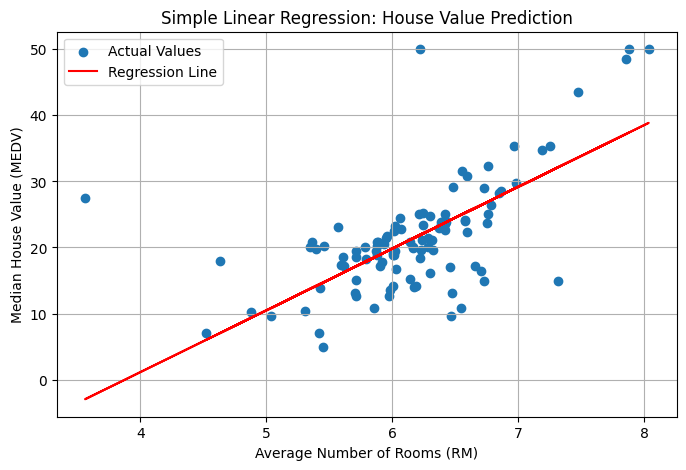

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(X_test["RM"], y_test, label="Actual Values")

plt.plot(
    X_test["RM"],
    y_pred,
    color="red",
    label="Regression Line"
)

plt.xlabel("Average Number of Rooms (RM)")
plt.ylabel("Median House Value (MEDV)")
plt.title("Simple Linear Regression: House Value Prediction")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("=" * 45)
print("CODVEDA MACHINE LEARNING INTERNSHIP")
print("LEVEL 1 - TASK 2: SIMPLE LINEAR REGRESSION")
print("=" * 45)

print(f"Total dataset records: {len(df)}")
print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")
print(f"Input feature: RM")
print(f"Target variable: MEDV")
print(f"Regression intercept: {model.intercept_:.4f}")
print(f"Regression coefficient: {model.coef_[0]:.4f}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")

print("=" * 45)

CODVEDA MACHINE LEARNING INTERNSHIP
LEVEL 1 - TASK 2: SIMPLE LINEAR REGRESSION
Total dataset records: 506
Training records: 404
Testing records: 102
Input feature: RM
Target variable: MEDV
Regression intercept: -36.2463
Regression coefficient: 9.3483
Mean Squared Error: 46.1448
R² Score: 0.3708
